In [10]:
from EAS_adaptado import *

## Definimos los parámetros fijos y los rangos de los hiperparámtros que buscamos optimizar

Como en la evaluación de parámetros de ACO ya sacamos los valores alpha, beta, rho y Q óptimos para nuestro tipo de problema, buscaremos ahora el valor óptimo de e

In [11]:
N = 30
T = 200
alpha = (np.linspace(1, 1.5, 5))
beta = (np.linspace(0.5, 5, 5))
rho = (np.linspace(0.2, 0.99, 5))
Q = (np.linspace(25, 100, 4))
e = np.linspace(1, 91, 5)

cerrado = True
random_state = (123, 1234, 12345)
inicio = 13

file_path = "data/matriz_distancias.csv"
dist_matrix = LoadDistanceMatrix(file_path)

## Realizamos la búsqueda en rejilla (grid search)

In [12]:
def ejecuta_config(N, T, alpha, beta, rho, Q, cerrado, random_state, inicio, dist_matrix, e):
    best_outputs, best_outputs_global, best_ant_f, best_ant_x = AntsColonyOptimization(N, T, alpha, beta, rho, Q, dist_matrix, cerrado, random_state, inicio, e)
    return {'options': (alpha, beta, rho, Q, e),
            'semilla': random_state,
            'outputs': best_outputs,
            'outputs_global': best_outputs_global,
            'fitness': best_ant_f,
            'solution': best_ant_x.copy()}

In [13]:
import itertools
import pandas as pd
from joblib import Parallel, delayed

combinaciones = list(itertools.product(alpha, beta, rho, Q, e, random_state))

resultados = Parallel(n_jobs=-1, verbose=10)(
    delayed(ejecuta_config)(N, T, a, b, r, q, cerrado, s, inicio, dist_matrix, ei)
    for a, b, r, q, ei, s in combinaciones)

filas = []
for res in resultados:
    a, b, r, q, e = res['options']
    filas.append({"alpha": a,
                  "beta": b,
                  "rho": r,
                  "Q": q,
                  "e": e,
                  "semilla": res['semilla'],
                  "fitness": res['fitness'],
                  "solution": res['solution']})

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:   21.0s
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:   38.4s
[Parallel(n_jobs=-1)]: Done  29 tasks      | elapsed:   40.1s
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   57.3s
[Parallel(n_jobs=-1)]: Done  53 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done  66 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  96 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 113 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done 130 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done 149 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:  3.3min
[Parallel(n_jobs=-1)]: Done 189 tasks      | elapsed:  3.7min
[Parallel(n_jobs=-1)]: Done 210 tasks      | elapsed:  4.2min
[Parallel(n_jobs=-1)]: Done 233 tasks      | elapsed:  

## Analisis de resultados

In [15]:
df = pd.DataFrame(filas)
df["solution"] = df["solution"].apply(list)

df.to_pickle("resultados_grid_eas.pkl")
df.drop(columns="solution").to_csv("resultados_grid_eas.csv", index=False)

resumen = (df.groupby(["alpha", "beta","rho", "Q", "e"])["fitness"]
             .agg(["mean", "std", "min"])
             .sort_values("mean")
             .reset_index())

resumen.head(10)

,alpha,beta,rho,Q,e,mean,std,min
0,1.125,1.625,0.2000,25.0,46.0,17858.748137,107.186342,17762.908210
1,1.000,3.875,0.2000,50.0,68.5,17859.908692,214.099990,17615.536390
2,1.000,3.875,0.2000,25.0,91.0,17915.786975,301.357670,17740.506597
3,1.000,1.625,0.3975,50.0,23.5,17921.508022,356.106340,17578.264671
4,1.000,1.625,0.5950,25.0,23.5,17929.529833,202.512329,17764.667234
5,1.125,2.750,0.2000,25.0,46.0,17933.003414,65.327803,17868.341891
6,1.000,1.625,0.3975,25.0,23.5,17937.048591,223.633560,17769.962942
7,1.250,3.875,0.2000,50.0,68.5,17942.358944,261.286201,17657.110238
8,1.000,1.625,0.2000,75.0,46.0,17948.489386,37.260053,17911.246442
9,1.000,3.875,0.2000,25.0,68.5,17950.704571,429.985047,17689.312547


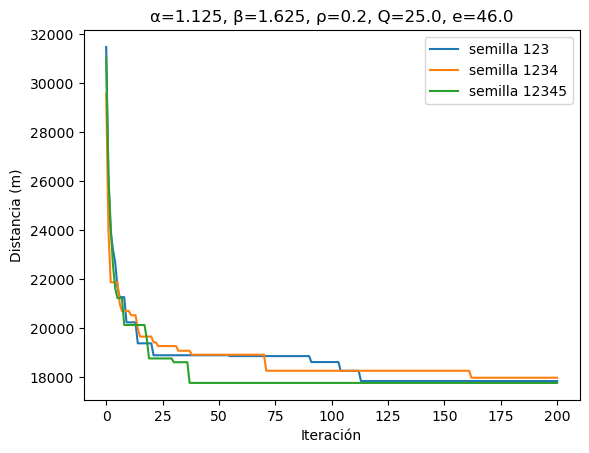

In [16]:
mejor = resumen.iloc[0]
for res in resultados:
    if res['options'] == (mejor.alpha, mejor.beta, mejor.rho, mejor.Q, mejor.e):
        plt.plot(res['outputs_global'], label=f"semilla {res['semilla']}")
plt.xlabel("Iteración"); plt.ylabel("Distancia (m)")
plt.title(f"α={mejor.alpha}, β={mejor.beta}, ρ={mejor.rho}, Q={mejor.Q}, e={mejor.e}")
plt.legend(); plt.show()